In [1]:
import os
import sys

import matplotlib.pyplot as plt
import torch
from PIL import Image
from torchvision import transforms

# add the project folder to the path to be able to import the models
sys.path.append(os.path.abspath(".."))
from models import vit_linear_probe, vit_lora, resnet50_linear_probe

# use the GPU if there is one
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cuda


## Load a model

In [2]:
MODEL = "vit_linear"  # "vit_linear", "vit_lora" or "resnet_linear"

if MODEL == "vit_linear":
    model, checkpoint = vit_linear_probe.load_model("../models/saved_models/vit_linear.pt", device)
elif MODEL == "vit_lora":
    model, checkpoint = vit_lora.load_model("../models/saved_models/vit_lora_r8_a16.pt", device)
elif MODEL == "resnet_linear":
    model, checkpoint = resnet50_linear_probe.load_model("../models/saved_models/resnet_linear.pt", device)

classes = checkpoint["classes"]

print(f"Loaded the {MODEL} model")
print(f"Image size: {checkpoint["image_size"]}x{checkpoint["image_size"]}")
print("Classes:", classes)

Loaded the vit_linear model
Image size: 128x128
Classes: ['1960s', '1970s', '1980s', '1990s', '2000s', '2010s']


## Prediction function

In [ ]:
def predict_image(path):
    # transform the image the same way as in training
    transform = transforms.Compose([
        transforms.Resize((checkpoint["image_size"], checkpoint["image_size"])),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])

    # load the image
    image = Image.open(path).convert("RGB")

    # the model expects a batch of images, so add a batch dimension
    x = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(x)

    # softmax turns the scores into probabilities that add up to 1
    probabilities = torch.softmax(outputs, dim=1)[0].cpu()
    best = probabilities.argmax().item()

    # show the image and the probability of every decade
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(image)
    plt.title(f"Predicted: {classes[best]} ({probabilities[best].item():.0%})")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.barh(classes, probabilities.tolist())
    plt.xlim(0, 1)
    plt.xlabel("Probability")
    plt.title(f"Probability per decade ({MODEL} model)")

    plt.tight_layout()
    plt.show()

## Run it on any image

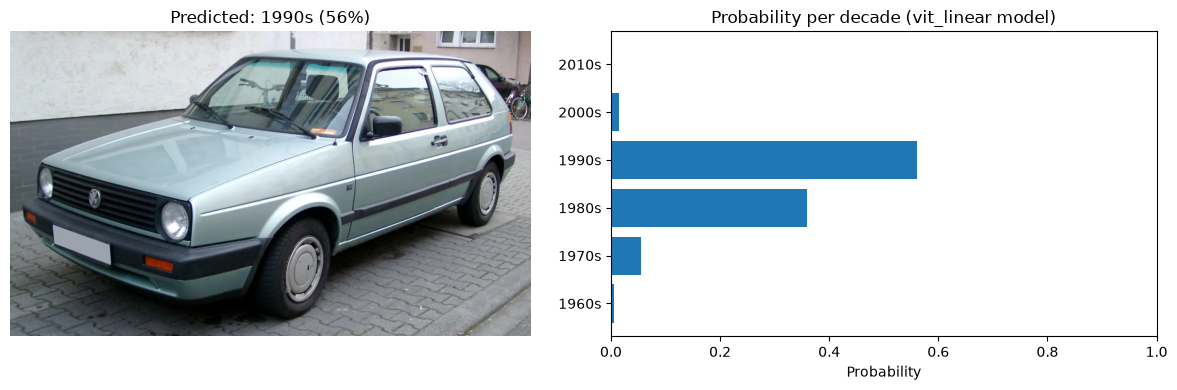

In [4]:
IMAGE_PATH = "../input/1.png"

predict_image(IMAGE_PATH)